# Regularization in Regression — Python companion
**Machine Learning for Biomedical Data (MLBD), Week 3**

This notebook follows the R lecture `lectures/week3/regularization.Rmd` section by section, replacing `glmnet` with scikit-learn's `Lasso`, `ElasticNet`, `LassoCV`, and `LogisticRegression`. It uses the same example datasets as the `glmnet` package.

## Bias-variance tradeoff and regularization
See the slides for the concepts. In short: penalizing (shrinking) coefficients adds a little bias but can greatly reduce variance and overfitting.

| | Penalty | Python |
|---|---|---|
| Ridge | L2: $\lambda\sum_j \beta_j^2$ | `Ridge` |
| Lasso | L1: $\lambda\sum_j \lvert\beta_j\rvert$ | `Lasso` |
| Elastic net | L1 + L2 | `ElasticNet` |


## glmnet ↔ scikit-learn: matching the parameters
`glmnet` minimizes
$$\frac{1}{2N}\sum_{i}(y_i-{\bf x}_i'\beta)^2 + \lambda\left[\alpha\|\beta\|_1 + \tfrac{1-\alpha}{2}\|\beta\|_2^2\right],$$
and scikit-learn's `ElasticNet` minimizes **exactly the same function**, with different names:

| glmnet | scikit-learn |
|---|---|
| `lambda` (penalty strength) | `alpha` |
| `alpha` (lasso/ridge mix; 1 = lasso) | `l1_ratio` |

⚠️ The names are swapped: glmnet's `alpha` is *not* scikit-learn's `alpha`.

One more difference: **glmnet standardizes the predictors** internally (then reports coefficients on the original scale); scikit-learn does not. So we standardize first and convert back. With that, the two give the same answers.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data live in python/data/ in the course repo. If you're running this
# notebook somewhere else (e.g., Google Colab), it falls back to GitHub.
LOCAL = "../data/"
REMOTE = "https://raw.githubusercontent.com/wevanjohnson/2026_Fall_MLBD/main/python/data/"
DATA = LOCAL if os.path.exists(LOCAL) else REMOTE
from sklearn.linear_model import Lasso, LassoCV, LogisticRegression, lasso_path
from sklearn.model_selection import KFold, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def to_original_scale(model, scaler):
    """Convert coefficients fit on standardized X back to the original scale (like glmnet)."""
    b = np.ravel(model.coef_) / scaler.scale_
    b0 = np.ravel(model.intercept_)[0] - np.sum(b * scaler.mean_)
    return b0, b

## Regression regularization: the glmnet quick start example

In [2]:
qs = pd.read_csv(DATA + "QuickStartExample.csv")
y = qs.pop("y").to_numpy()
x = qs.to_numpy()
names = qs.columns
x.shape

(100, 20)

The equivalent of `fit <- glmnet(x, y)`: the whole **lasso path** over a grid of λ values.

In [3]:
scaler = StandardScaler().fit(x)
xs = scaler.transform(x)

# glmnet's default lambda sequence: 100 values from lambda_max down to 1e-4 * lambda_max
lam_max = np.max(np.abs(xs.T @ (y - y.mean()))) / len(y)
lambdas = np.geomspace(lam_max, lam_max * 1e-4, 100)
lambdas, coefs_std, _ = lasso_path(xs, y - y.mean(), alphas=lambdas)
coefs = coefs_std / scaler.scale_[:, None]          # back to the original scale
coefs.shape                                          # (predictors, lambdas)

(20, 100)

Coefficient paths, like `plot(fit)`: each line is one predictor, plotted against the L1 norm of the coefficient vector.

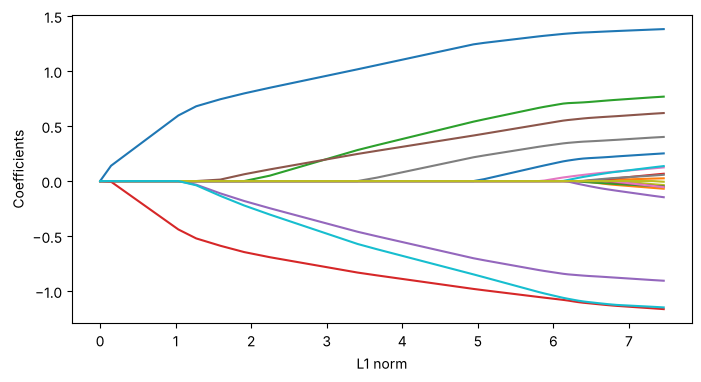

In [4]:
l1_norm = np.abs(coefs).sum(axis=0)
plt.figure(figsize=(8, 4))
for j in range(coefs.shape[0]):
    plt.plot(l1_norm, coefs[j])
plt.xlabel("L1 norm"); plt.ylabel("Coefficients")
plt.show()

A summary along the path, like `print(fit)`: number of nonzero coefficients (Df), % deviance explained, and λ.

In [5]:
def pct_dev(b):
    b0 = y.mean() - x.mean(axis=0) @ b
    rss = np.sum((y - b0 - x @ b) ** 2)
    return 100 * (1 - rss / np.sum((y - y.mean()) ** 2))

path = pd.DataFrame({"Df": (coefs != 0).sum(axis=0),
                     "%Dev": [round(pct_dev(coefs[:, k]), 2) for k in range(coefs.shape[1])],
                     "Lambda": lambdas.round(4)})
path.iloc[::8]

,Df,%Dev,Lambda
0,0,0.00,1.6308
8,5,51.54,0.7747
16,7,80.53,0.3681
24,8,88.21,0.1749
32,9,90.23,0.0831
40,16,90.93,0.0395
48,19,91.22,0.0187
56,19,91.30,0.0089
64,20,91.32,0.0042
72,20,91.32,0.0020


Coefficients at a single λ, like `coef(fit, s = 0.1)`. These match the glmnet vignette (to within glmnet's convergence tolerance).

In [6]:
m = Lasso(alpha=0.1).fit(xs, y)
b0, b = to_original_scale(m, scaler)
pd.Series(np.r_[b0, b], index=["(Intercept)"] + list(names)).round(4).replace(0, ".")

(Intercept)    0.1509
V1             1.3206
V2                  .
V3             0.6751
V4                  .
V5            -0.8174
V6             0.5214
V7             0.0048
V8             0.3194
V9                  .
V10                 .
V11            0.1425
V12                 .
V13                 .
V14             -1.06
V15                 .
V16                 .
V17                 .
V18                 .
V19                 .
V20           -1.0219
dtype: object

## Choosing λ by cross-validation
`cv.glmnet(x, y)` → `LassoCV`. We plot the CV mean squared error (± 1 SE) against log(λ), like `plot(cvfit)`.

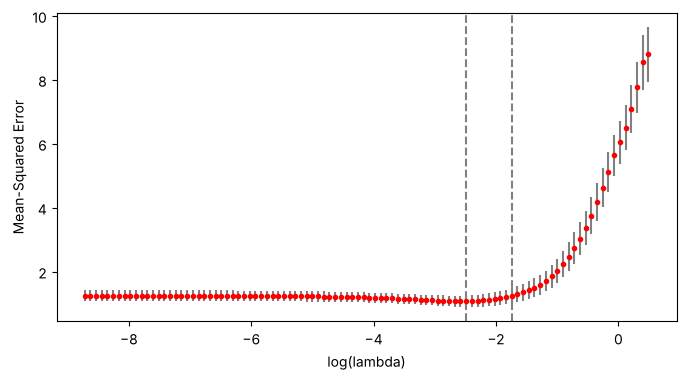

In [7]:
cvfit = make_pipeline(StandardScaler(),
                      LassoCV(alphas=lambdas, cv=KFold(10, shuffle=True, random_state=1)))
cvfit.fit(x, y)
lasso_cv = cvfit[-1]

mse = lasso_cv.mse_path_.mean(axis=1)
se = lasso_cv.mse_path_.std(axis=1) / np.sqrt(lasso_cv.mse_path_.shape[1])
lam_min = lasso_cv.alpha_
lam_1se = lasso_cv.alphas_[np.argmax(mse <= mse[np.argmin(mse)] + se[np.argmin(mse)])]

plt.figure(figsize=(8, 4))
plt.errorbar(np.log(lasso_cv.alphas_), mse, yerr=se, fmt="o", color="red", ecolor="gray", ms=3)
for lam in (lam_min, lam_1se):
    plt.axvline(np.log(lam), ls="--", color="gray")
plt.xlabel("log(lambda)"); plt.ylabel("Mean-Squared Error")
plt.show()

$\lambda_{min}$ and its coefficients, like `coef(cvfit, s = "lambda.min")`:

In [8]:
print("lambda.min:", round(lam_min, 4), "| lambda.1se:", round(lam_1se, 4))
b0, b = to_original_scale(lasso_cv, cvfit[0])
pd.Series(np.r_[b0, b], index=["(Intercept)"] + list(names)).round(4).replace(0, ".")

lambda.min: 0.0831 | lambda.1se: 0.1749


(Intercept)    0.1494
V1             1.3298
V2                  .
V3              0.691
V4                  .
V5            -0.8312
V6             0.5367
V7             0.0201
V8             0.3319
V9                  .
V10                 .
V11            0.1624
V12                 .
V13                 .
V14           -1.0708
V15                 .
V16                 .
V17                 .
V18                 .
V19                 .
V20           -1.0434
dtype: object

> CV folds are random, so λ<sub>min</sub> will differ a little from the R slides (and from run to run in R, too).

## Example: logistic regression elastic net
For a binary response, glmnet minimizes $-\frac{1}{N}\,\text{log-likelihood} + \lambda \times \text{penalty}$.

scikit-learn's `LogisticRegression` instead minimizes $C \times (-\text{log-likelihood}) + \text{penalty}$, so **$C = 1/(N\lambda)$**. We use `solver="saga"`, which supports the L1 penalty.

In [9]:
bx = pd.read_csv(DATA + "BinomialExample.csv")
by = bx.pop("y").to_numpy()
bX = bx.to_numpy()
N = len(by)
bX.shape, np.bincount(by.astype(int))

((100, 30), array([44, 56]))

In [10]:
import sklearn
from packaging.version import Version

def lasso_logistic(C):
    """L1-penalized logistic regression (glmnet family = "binomial", alpha = 1)."""
    if Version(sklearn.__version__) >= Version("1.8"):
        return LogisticRegression(l1_ratio=1.0, C=C, solver="saga", max_iter=20000)
    return LogisticRegression(penalty="l1", C=C, solver="saga", max_iter=20000)

10-fold CV using **misclassification error** (`type.measure = "class"`):

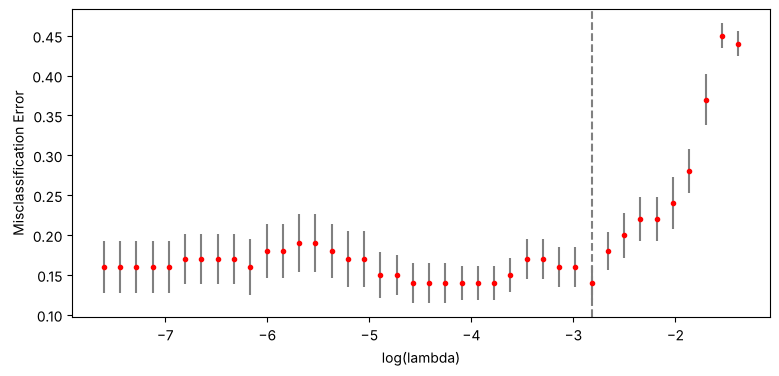

lambda.min: 0.0596


In [11]:
lam_grid = np.logspace(np.log10(0.25), np.log10(0.0005), 40)

search = GridSearchCV(
    make_pipeline(StandardScaler(), lasso_logistic(C=1.0)),
    param_grid={"logisticregression__C": 1 / (N * lam_grid)},
    cv=StratifiedKFold(10, shuffle=True, random_state=1),
    scoring="accuracy")
search.fit(bX, by)

err = 1 - search.cv_results_["mean_test_score"]
err_se = search.cv_results_["std_test_score"] / np.sqrt(10)
best_lam = 1 / (N * search.best_params_["logisticregression__C"])

plt.figure(figsize=(9, 4))
plt.errorbar(np.log(lam_grid), err, yerr=err_se, fmt="o", color="red", ecolor="gray", ms=3)
plt.axvline(np.log(best_lam), ls="--", color="gray")
plt.xlabel("log(lambda)"); plt.ylabel("Misclassification Error")
plt.show()
print("lambda.min:", round(best_lam, 4))

Coefficients at $\lambda_{min}$ (on the original scale). Many are exactly zero: the lasso selected variables.

In [12]:
best = search.best_estimator_
b0, b = to_original_scale(best[-1], best[0])
coef = pd.Series(np.r_[b0, b], index=["(Intercept)"] + list(bx.columns)).round(4)
print("nonzero coefficients:", int((coef.iloc[1:] != 0).sum()), "of", len(coef) - 1)
coef.replace(0, ".")

nonzero coefficients: 12 of 30


(Intercept)    0.2076
V1                  .
V2             0.2227
V3            -0.1033
V4            -0.6343
V5            -0.0796
V6            -0.3336
V7                  .
V8            -0.1845
V9             0.1384
V10           -0.6431
V11                 .
V12                 .
V13                 .
V14                 .
V15                 .
V16                 .
V17                 .
V18                 .
V19                 .
V20                 .
V21                 .
V22            0.0738
V23            0.0293
V24                 .
V25            0.2144
V26           -0.1297
V27                 .
V28                 .
V29                 .
V30                 .
dtype: object

## Session info

In [13]:
import sys, matplotlib
print("Python", sys.version.split()[0])
print("numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

Python 3.13.16
numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | matplotlib 3.11.2
